In [1]:
import os
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image, make_grid
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset_path = "/kaggle/input/datasets/soumikrakshit/anime-faces"
dataset = datasets.ImageFolder(root=dataset_path, transform=transform)
dataloader = DataLoader(dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)

print("Total images:", len(dataset))
print("Number of batches:", len(dataloader))

Using device: cuda
GPU Name: Tesla T4
Total images: 43102
Number of batches: 337


In [2]:
class Generator(nn.Module):
    def __init__(self, nz=100, ngf=64, nc=3):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, input):
        return self.main(input)

class Discriminator(nn.Module):
    def __init__(self, nc=3, ndf=64):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        return self.main(input).view(-1, 1).squeeze(1)

nz = 100
netG = Generator(nz=nz).to(device)
netD = Discriminator().to(device)
print("Generator and Discriminator created successfully!")

Generator and Discriminator created successfully!


In [3]:
criterion = nn.BCELoss()
optimizerD = optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))

fixed_noise = torch.randn(64, nz, 1, 1, device=device)
num_epochs = 40

G_losses = []
D_losses = []
img_list = []

print("Training setup done! Epochs:", num_epochs)

Training setup done! Epochs: 40


In [4]:
print("Starting Training...")

for epoch in range(num_epochs):
    for i, (real_images, _) in enumerate(tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")):
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # ----- Train Discriminator -----
        netD.zero_grad()

        label_real = torch.full((batch_size,), 1.0, dtype=torch.float, device=device)
        output = netD(real_images)
        errD_real = criterion(output, label_real)
        errD_real.backward()

        noise = torch.randn(batch_size, nz, 1, 1, device=device)
        fake = netG(noise)
        label_fake = torch.full((batch_size,), 0.0, dtype=torch.float, device=device)
        output = netD(fake.detach())
        errD_fake = criterion(output, label_fake)
        errD_fake.backward()

        errD = errD_real + errD_fake
        optimizerD.step()

        # ----- Train Generator -----
        netG.zero_grad()
        label_real = torch.full((batch_size,), 1.0, dtype=torch.float, device=device)
        output = netD(fake)
        errG = criterion(output, label_real)
        errG.backward()
        optimizerG.step()

        # ★ Loss tracking (har batch pe)
        G_losses.append(errG.item())
        D_losses.append(errD.item())

    # Har epoch ke end pe image save
    with torch.no_grad():
        fake = netG(fixed_noise).detach().cpu()
    img_list.append(make_grid(fake, padding=2, normalize=True))
    save_image(fake, f"dcgan_epoch_{epoch+1:02d}.png", normalize=True, nrow=8)

    print(f"Epoch [{epoch+1}/{num_epochs}]  Loss_D: {errD.item():.4f}  Loss_G: {errG.item():.4f}")

print("Training Finished!")
print("Total loss points recorded:", len(G_losses))

Starting Training...


Epoch 1/40:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch [1/40]  Loss_D: 0.5018  Loss_G: 3.8545


Epoch 2/40:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch [2/40]  Loss_D: 0.3289  Loss_G: 4.7652


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79bac9139120>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79bac9139120>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [39/40]  Loss_D: 0.0809  Loss_G: 4.9464


Epoch 40/40:   0%|          | 0/337 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79bac9139120><function _MultiProcessingDataLoaderIter.__del__ at 0x79bac9139120>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()    
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

Exception ignored in:   File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getp

Epoch [40/40]  Loss_D: 0.0590  Loss_G: 4.5429
Training Finished!
Total loss points recorded: 13480


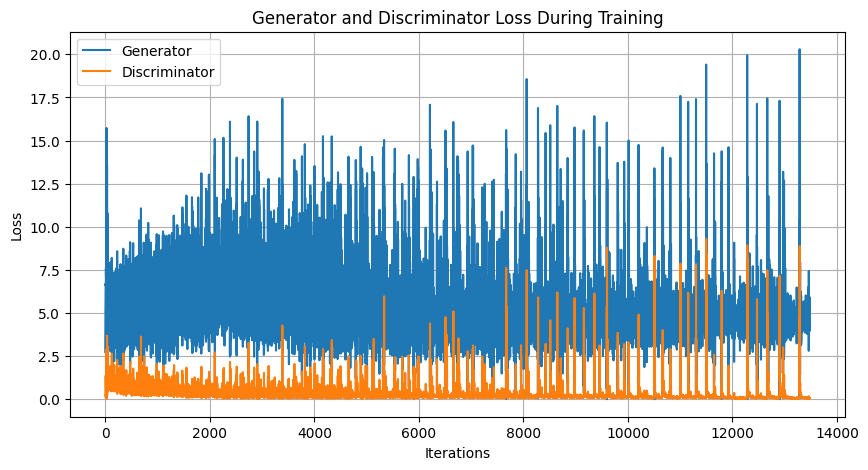

In [5]:
plt.figure(figsize=(10, 5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="Generator")
plt.plot(D_losses, label="Discriminator")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig("loss_plot.png", dpi=150, bbox_inches="tight")
plt.show()

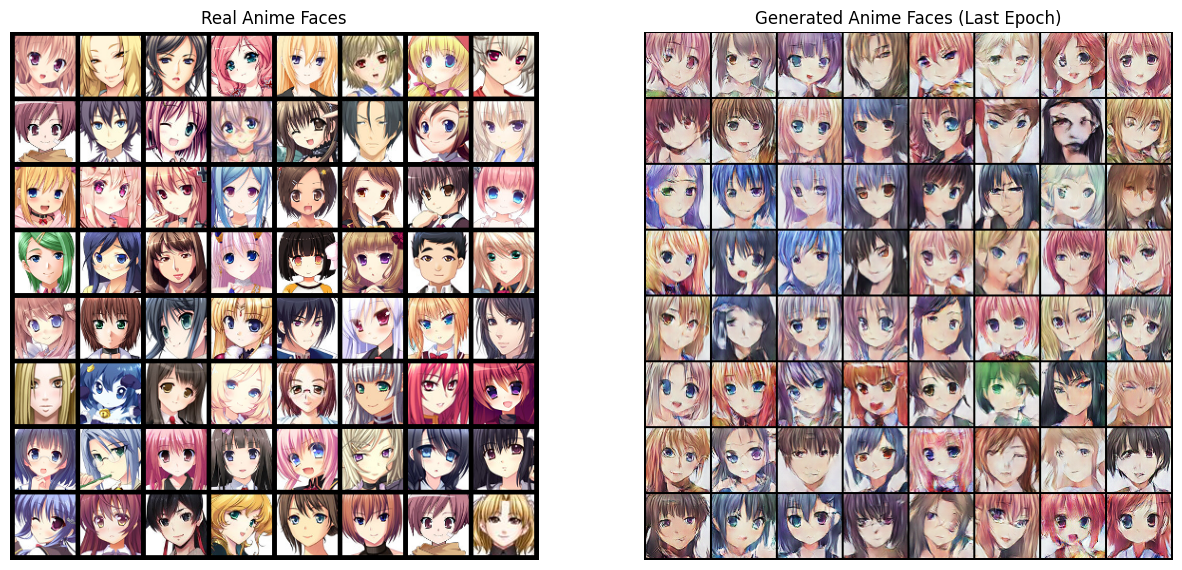

In [6]:
real_batch = next(iter(dataloader))

plt.figure(figsize=(15, 8))

plt.subplot(1, 2, 1)
plt.axis("off")
plt.title("Real Anime Faces")
plt.imshow(np.transpose(make_grid(real_batch[0][:64], padding=5, normalize=True).cpu(), (1, 2, 0)))

plt.subplot(1, 2, 2)
plt.axis("off")
plt.title("Generated Anime Faces (Last Epoch)")
plt.imshow(np.transpose(img_list[-1], (1, 2, 0)))

plt.savefig("real_vs_fake.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
netG.eval()
with torch.no_grad():
    noise = torch.randn(64, 100, 1, 1, device=device)
    fake = netG(noise).cpu()
save_image(fake, "final_anime_faces.png", normalize=True, nrow=8)
print("Final images saved as final_anime_faces.png")

torch.save(netG.state_dict(), "dcgan_generator.pth")
torch.save(netD.state_dict(), "dcgan_discriminator.pth")
print("Models saved successfully!")

Final images saved as final_anime_faces.png
Models saved successfully!
